In [1]:
!pip install -q -U ultralytics nest_asyncio
import nest_asyncio

nest_asyncio.apply()
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [2]:
from google.colab import files

archivos = files.upload()
ndjson_path = next(iter(archivos))
print(f"Archivo cargado: {ndjson_path}")

Saving helmet-detection-model.ndjson to helmet-detection-model.ndjson
Archivo cargado: helmet-detection-model.ndjson


In [3]:
model = YOLO("yolo26n.pt")
results = model.train(
    data=ndjson_path,
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    project="proyecto_cascos",
    name="entrenamiento_yolo26",
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=helmet-detection-model.ndjson, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=entrenamiento_yolo26, nbs=64, nms=None, opset=None, optimiz

In [6]:
!pip install -q yt-dlp

url_youtube = "https://youtube.com/shorts/CrCGsJFoHoI"

!yt-dlp -f "bv*+ba/b" --merge-output-format mp4 -o "/content/video_prueba.mp4" "{url_youtube}"

[youtube] Extracting URL: https://youtube.com/shorts/CrCGsJFoHoI
[youtube] CrCGsJFoHoI: Downloading webpage
[youtube] CrCGsJFoHoI: Downloading visionos player API JSON
[youtube] CrCGsJFoHoI: Downloading m3u8 information
[info] CrCGsJFoHoI: Downloading 1 format(s): 399+251
[download] Destination: /content/video_prueba.f399.mp4
[download] 100% of    9.09MiB in 00:00:01 at 7.32MiB/s
[download] Destination: /content/video_prueba.f251.webm
[download] 100% of  746.18KiB in 00:00:00 at 748.53KiB/s
[Merger] Merging formats into "/content/video_prueba.mp4"
Deleting original file /content/video_prueba.f399.mp4 (pass -k to keep)
Deleting original file /content/video_prueba.f251.webm (pass -k to keep)


Matriz de Transición de Markov (P):
 [[      0.625       0.125        0.25]
 [      0.023       0.795       0.182]
 [      0.013        0.01       0.977]]

[Escenario Base] Probabilidad estacionaria [Cumplimiento, Parcial, Crítico]: [      0.036       0.066       0.899]
[Escenario Intervención] Probabilidad estacionaria [Cumplimiento, Parcial, Crítico]: [      0.504       0.317       0.179]


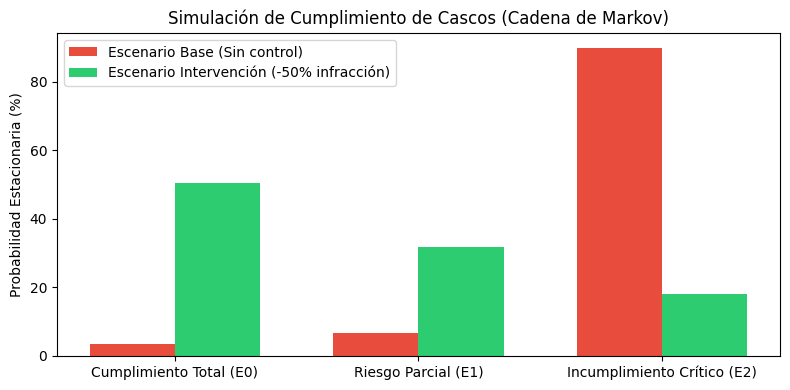

In [7]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

# 1. Cargar tu modelo ya entrenado
model = YOLO(
    "/content/runs/detect/proyecto_cascos/entrenamiento_yolo26/weights/best.pt"
)

# 2. Abrir video de prueba y configurar el video de salida con detecciones
video_path = "/content/video_prueba.mp4"
cap = cv2.VideoCapture(video_path)

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS)) or 30
out = cv2.VideoWriter(
    "/content/resultado_cascos.mp4",
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height),
)

estados_observados = []

while cap.isOpened():
  ret, frame = cap.read()
  if not ret:
    break

  # Inferencia con YOLO26
  results = model(frame, conf=0.4, verbose=False)[0]
  out.write(results.plot())  # Dibuja las cajas (helmet / no_helmet)

  # Conteo de clases (0: no_helmet, 1: helmet)
  clases = results.boxes.cls.cpu().numpy().astype(int)
  sin_casco = np.sum(clases == 0)
  con_casco = np.sum(clases == 1)

  # Clasificar estado del sistema en el fotograma actual
  if sin_casco == 0 and con_casco > 0:
    estado = 0  # E0: Cumplimiento total
  elif sin_casco > 0 and con_casco > 0:
    estado = 1  # E1: Riesgo parcial
  elif sin_casco > 0 and con_casco == 0:
    estado = 2  # E2: Incumplimiento crítico
  else:
    continue

  estados_observados.append(estado)

cap.release()
out.release()

# 3. Construir Matriz de Transición de Markov (3x3)
matriz_conteos = np.zeros((3, 3))
for t in range(len(estados_observados) - 1):
  i, j = estados_observados[t], estados_observados[t + 1]
  matriz_conteos[i, j] += 1

P = np.zeros((3, 3))
for i in range(3):
  suma_fila = np.sum(matriz_conteos[i])
  P[i] = matriz_conteos[i] / suma_fila if suma_fila > 0 else np.eye(3)[i]

print("Matriz de Transición de Markov (P):\n", np.round(P, 3))

# 4. Simulación de Escenarios (Base vs Intervención)
estado_inicial = np.array([1.0, 0.0, 0.0])  # Inicia en Cumplimiento Total
dist_base = estado_inicial @ np.linalg.matrix_power(P, 50)

P_intervencion = P.copy()
P_intervencion[:, 2] *= 0.5  # Simula reducir en 50% las transiciones críticas
P_intervencion[:, 0] += P[:, 2] * 0.5
dist_intervencion = estado_inicial @ np.linalg.matrix_power(P_intervencion, 50)

print(
    "\n[Escenario Base] Probabilidad estacionaria [Cumplimiento, Parcial,"
    " Crítico]:",
    np.round(dist_base, 3),
)
print(
    "[Escenario Intervención] Probabilidad estacionaria [Cumplimiento, Parcial,"
    " Crítico]:",
    np.round(dist_intervencion, 3),
)

# 5. Gráfica comparativa para la sustentación
estados_labels = [
    "Cumplimiento Total (E0)",
    "Riesgo Parcial (E1)",
    "Incumplimiento Crítico (E2)",
]
x = np.arange(len(estados_labels))
width_bar = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    x - width_bar / 2,
    dist_base * 100,
    width_bar,
    label="Escenario Base (Sin control)",
    color="#e74c3c",
)
ax.bar(
    x + width_bar / 2,
    dist_intervencion * 100,
    width_bar,
    label="Escenario Intervención (-50% infracción)",
    color="#2ecc71",
)

ax.set_ylabel("Probabilidad Estacionaria (%)")
ax.set_title("Simulación de Cumplimiento de Cascos (Cadena de Markov)")
ax.set_xticks(x)
ax.set_xticklabels(estados_labels)
ax.legend()
plt.tight_layout()
plt.savefig("/content/simulacion_markov.png", dpi=300)
plt.show()